In [ ]:
!pip install -q dvc
!pip install -q pandas numpy matplotlib seaborn scipy scikit-learn pillow tqdm

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
# Clone Project Repository

!git clone https://github.com/joshbrgs/ai-570.git

%cd ai-570

Cloning into 'ai-570'...
remote: Enumerating objects: 55, done.
remote: Counting objects: 100% (55/55), done.
remote: Compressing objects: 100% (41/41), done.
remote: Total 55 (delta 9), reused 54 (delta 8), pack-reused 0 (from 0)
Receiving objects: 100% (55/55), 2.10 MiB | 15.25 MiB/s, done.
Resolving deltas: 100% (9/9), done.
/content/ai-570


In [ ]:
# Download DVC-tracked raw files

!dvc update data/raw/*.dvc


Streaming output truncated to the last 5000 lines.
 45% 1.40G/3.12G [09:49<15:41, 1.96MB/s{'info': ''}]
 45% 1.40G/3.12G [09:49<14:55, 2.06MB/s{'info': ''}]
 45% 1.40G/3.12G [09:49<14:41, 2.09MB/s{'info': ''}]
 45% 1.40G/3.12G [09:49<14:05, 2.18MB/s{'info': ''}]
 45% 1.40G/3.12G [09:49<15:36, 1.97MB/s{'info': ''}]
 45% 1.41G/3.12G [09:49<14:46, 2.08MB/s{'info': ''}]
 45% 1.41G/3.12G [09:50<14:39, 2.10MB/s{'info': ''}]
 45% 1.41G/3.12G [09:50<13:57, 2.20MB/s{'info': ''}]
 45% 1.41G/3.12G [09:50<12:57, 2.37MB/s{'info': ''}]
 45% 1.41G/3.12G [09:50<12:11, 2.52MB/s{'info': ''}]
 45% 1.41G/3.12G [09:50<10:46, 2.85MB/s{'info': ''}]
 45% 1.41G/3.12G [09:50<12:33, 2.45MB/s{'info': ''}]
 45% 1.41G/3.12G [09:51<12:42, 2.41MB/s{'info': ''}]
 45% 1.41G/3.12G [09:51<12:56, 2.37MB/s{'info': ''}]
 45% 1.41G/3.12G [09:51<13:14, 2.32MB/s{'info': ''}]
 45% 1.41G/3.12G [09:51<13:07, 2.34MB/s{'info': ''}]
 45% 1.41G/3.12G [09:51<13:25, 2.28MB/s{'info': ''}]
 45% 1.41G/3.12G [09:51<13:36, 2.25MB/s{'info': 

# Baseline CNN: bars and spiral-arm tightness (Keras / TensorFlow)

This notebook cleans the GZ2 table into a labelled dataset, splits it by galaxy, and
trains a two-head CNN baseline:

| Head | Question | Target | Loss | Metric |
|------|----------|--------|------|--------|
| `bar` | t03: is there a bar? | 1 if debiased bar fraction ≥ 0.5 | binary cross-entropy | accuracy |
| `winding` | t10: how tightly wound are the arms? | debiased (tight, medium, loose) fractions | MSE | RMSE |


In [ ]:
import time

import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from keras import layers
from sklearn.model_selection import train_test_split

from gz2.data import PROCESSED_DIR, ROOT, load_galaxies

SEED = 42
MIN_VOTES = 10            # minimum volunteers on a question for its label to count
BAR_THRESHOLD = 0.5
SPLIT = (0.80, 0.10, 0.10)
IMG_SIZE = 128
BATCH_SIZE = 64
EPOCHS = 15
LOSS_WEIGHTS = {"bar": 1.0, "winding": 0.5}
SMOKE_TEST = False        # True = tiny subset + 1 epoch, to check the pipeline end to end

WINDING_COLS = ["t10_tight", "t10_medium", "t10_loose"]
OUTPUT_DIR = ROOT / "output"
MODELS_DIR = ROOT / "models"
for d in (OUTPUT_DIR, MODELS_DIR, PROCESSED_DIR):
    d.mkdir(exist_ok=True)

keras.utils.set_random_seed(SEED)
print("TensorFlow", tf.__version__, "| devices:", [d.device_type for d in tf.config.list_physical_devices()])

TensorFlow 2.21.0 | devices: ['CPU', 'GPU']


## 1. Load

`load_galaxies()` in `gz2/data.py` returns the same one-row-per-galaxy frame the EDA notebook
builds, plus `tNN_votes` columns that count how many volunteers answered each question.

In [14]:
import zipfile
from pathlib import Path
from gz2.data import IMAGES_DIR, ROOT

# The ZIP file contains an 'images/' folder.
# Extracting it into the parent of 'images' will result in /content/ai-570/data/images/
print(f"Extracting images_gz2.zip to {IMAGES_DIR.parent}...")
with zipfile.ZipFile('data/raw/images_gz2.zip', 'r') as zip_ref:
    zip_ref.extractall(IMAGES_DIR.parent)

print(f"Extraction completed! Number of images in {IMAGES_DIR}: {len(list(IMAGES_DIR.glob('*.jpg'))):,}")

Extracting images_gz2.zip to /content/ai-570/data...
Extraction completed! Number of images in /content/ai-570/data/images: 243,434


In [16]:
df = load_galaxies()
print(f"{len(df):,} galaxies x {df.shape[1]} cols")
df[["dr7objid", "gz2_class", "t03_bar", "t03_votes", *WINDING_COLS, "t10_votes", "has_image"]].head()

239,695 galaxies x 59 cols


,dr7objid,gz2_class,t03_bar,t03_votes,t10_tight,t10_medium,t10_loose,t10_votes,has_image
0,587732591714893851,Sc+t,0.025,40,0.676487,0.301320,0.025,40,True
1,588009368545984617,Sb+t,0.080,41,0.871056,0.080068,0.050,41,True
2,587732484359913515,Ei,0.400,5,0.000000,0.000000,0.000,0,True
3,587741723357282317,Sc+t,0.038,26,0.640306,0.319844,0.040,25,True
4,587738410866966577,Er,0.000,7,0.000000,0.000000,0.000,0,True


## 2. Clean

The bar and winding questions sit deep in the GZ2 decision tree, so most galaxies were asked them
by only a handful of volunteers (median 5 for t03, 1 for t10). A label counts only if at least
`MIN_VOTES` volunteers answered. A galaxy is kept if it has an image and at least one usable label.
The other head is **masked** with a sample weight of 0, so every galaxy still contributes to
training.

In [17]:
clean = df[df["has_image"]].copy()

clean["bar_weight"] = (clean["t03_votes"] >= MIN_VOTES) & clean["t03_bar"].notna()
clean["bar_label"] = (clean["t03_bar"] >= BAR_THRESHOLD).astype("float32")

winding = clean[WINDING_COLS].fillna(0.0)
winding_total = winding.sum(axis=1)
clean["winding_weight"] = (clean["t10_votes"] >= MIN_VOTES) & (winding_total > 0)
# Debiased fractions don't always sum to exactly 1; renormalise so they match a softmax output.
clean[WINDING_COLS] = winding.div(winding_total.where(winding_total > 0, 1.0), axis=0)

clean = clean[clean["bar_weight"] | clean["winding_weight"]].reset_index(drop=True)
clean[["bar_weight", "winding_weight"]] = clean[["bar_weight", "winding_weight"]].astype("float32")

funnel = pd.Series({
    "all galaxies": len(df),
    "with image": int(df["has_image"].sum()),
    f"usable bar label (t03 >= {MIN_VOTES} votes)": int(clean["bar_weight"].sum()),
    f"usable winding label (t10 >= {MIN_VOTES} votes)": int(clean["winding_weight"].sum()),
    "both labels": int((clean["bar_weight"] * clean["winding_weight"]).sum()),
    "kept (either label)": len(clean),
}, name="galaxies")
funnel.to_frame().style.format("{:,}")

,galaxies
all galaxies,"239,695"
with image,"239,573"
usable bar label (t03 >= 10 votes),"80,556"
usable winding label (t10 >= 10 votes),"51,104"
both labels,"51,103"
kept (either label),"80,557"


In [18]:
bar_rows = clean[clean["bar_weight"] == 1]
wind_rows = clean[clean["winding_weight"] == 1]
print(f"Bar label balance: {bar_rows['bar_label'].mean():.1%} barred")
print("Winding mean fractions:", wind_rows[WINDING_COLS].mean().round(3).to_dict())

Bar label balance: 40.0% barred
Winding mean fractions: {'t10_tight': 0.436, 't10_medium': 0.403, 't10_loose': 0.161}


## 3. Split by galaxy

There's one row per `dr7objid`, so no galaxy can land in two splits. The split is stratified on
which labels a galaxy has and on its bar class, so every split gets the same mix. It's saved to
`data/processed/` so the CNN, JAX/Flax and ViT experiments all train and test on identical sets.

In [19]:
# Stratum = bar class (0 = no label, 1 = no bar, 2 = bar) x has-winding-label; tiny strata fold into the largest.
strata = (
    (clean["bar_weight"] * (1 + clean["bar_label"])).astype(int).astype(str)
    + "_" + clean["winding_weight"].astype(int).astype(str)
)
strata = strata.where(strata.map(strata.value_counts()) >= 10, strata.mode()[0])

train_ids, holdout_ids = train_test_split(
    clean["dr7objid"], test_size=SPLIT[1] + SPLIT[2], stratify=strata, random_state=SEED
)
val_ids, test_ids = train_test_split(
    holdout_ids,
    test_size=SPLIT[2] / (SPLIT[1] + SPLIT[2]),
    stratify=strata[holdout_ids.index],
    random_state=SEED,
)
clean["split"] = "train"
clean.loc[val_ids.index, "split"] = "val"
clean.loc[test_ids.index, "split"] = "test"

assert clean["dr7objid"].is_unique
print(clean.groupby("split")[["bar_weight", "bar_label", "winding_weight"]].agg(["sum", "mean"]).round(3))

split_cols = ["dr7objid", "asset_id", "split", "bar_label", "bar_weight", *WINDING_COLS, "winding_weight"]
split_path = PROCESSED_DIR / "gz2_bar_winding_v1.csv"
clean[split_cols].to_csv(split_path, index=False)
print(f"Saved {len(clean):,} rows -> {split_path.relative_to(ROOT)}")

      bar_weight      bar_label      winding_weight       
             sum mean       sum mean            sum   mean
split                                                     
test      8056.0  1.0    3224.0  0.4         5110.0  0.634
train    64444.0  1.0   25790.0  0.4        40882.0  0.634
val       8056.0  1.0    3224.0  0.4         5112.0  0.635
Saved 80,557 rows -> data/processed/gz2_bar_winding_v1.csv


## 4. Input pipeline (`tf.data`)

- Centre-crop 424 → 212 px (the galaxy is always centred) and resize to `IMG_SIZE`.
- Training augmentation uses random flips and 90° rotations only, since morphology doesn't depend
  on orientation. There's **no hue or brightness jitter** because colour tracks morphology.
- Each element is `(image, {head: label}, {head: sample_weight})`.

In [20]:
if SMOKE_TEST:
    clean = clean.sample(n=2_000, random_state=SEED)
    EPOCHS = 1


def load_image(path: tf.Tensor) -> tf.Tensor:
    image = tf.io.decode_jpeg(tf.io.read_file(path), channels=3)
    image = tf.image.central_crop(image, 0.5)
    return tf.image.resize(image, (IMG_SIZE, IMG_SIZE), antialias=True)  # float32 in [0, 255]


def augment(image: tf.Tensor) -> tf.Tensor:
    image = tf.image.random_flip_left_right(image)
    image = tf.image.random_flip_up_down(image)
    return tf.image.rot90(image, k=tf.random.uniform([], 0, 4, dtype=tf.int32))


def make_dataset(frame: pd.DataFrame, training: bool) -> tf.data.Dataset:
    ds = tf.data.Dataset.from_tensor_slices((
        frame["image_path"].to_numpy(),
        {
            "bar": frame["bar_label"].to_numpy("float32")[:, None],
            "winding": frame[WINDING_COLS].to_numpy("float32"),
        },
        {
            "bar": frame["bar_weight"].to_numpy("float32"),
            "winding": frame["winding_weight"].to_numpy("float32"),
        },
    ))
    if training:
        ds = ds.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)

    def prepare(path, labels, weights):
        image = load_image(path)
        return (augment(image) if training else image), labels, weights

    return ds.map(prepare, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


frames = {name: clean[clean["split"] == name] for name in ("train", "val", "test")}
train_ds = make_dataset(frames["train"], training=True)
val_ds = make_dataset(frames["val"], training=False)
test_ds = make_dataset(frames["test"], training=False)

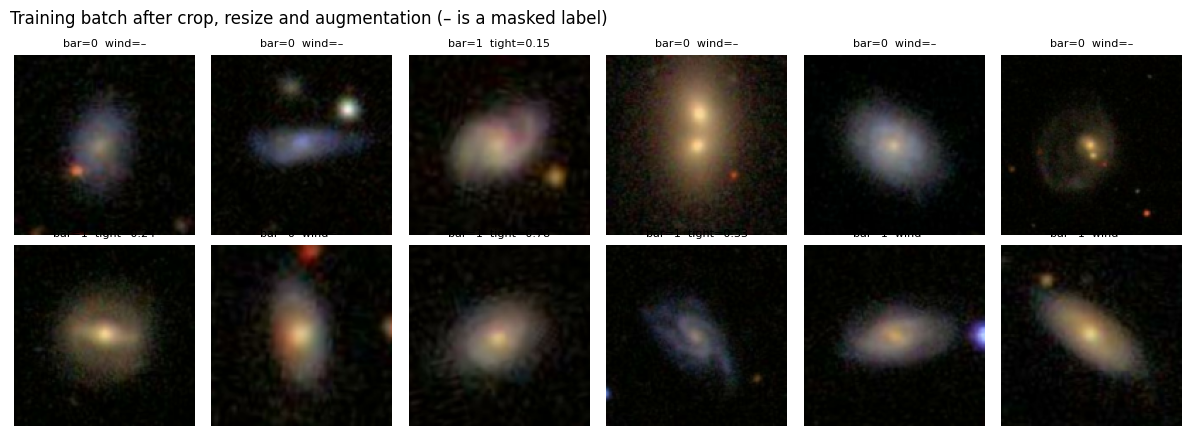

In [21]:
images, labels, weights = next(iter(train_ds))
fig, axes = plt.subplots(2, 6, figsize=(12, 4.4))
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].numpy().astype("uint8"))
    bar = f"bar={int(labels['bar'][i, 0])}" if weights["bar"][i] else "bar=–"
    tight = f"tight={labels['winding'][i, 0]:.2f}" if weights["winding"][i] else "wind=–"
    ax.set_title(f"{bar}  {tight}", fontsize=8)
    ax.axis("off")
fig.suptitle("Training batch after crop, resize and augmentation (– is a masked label)", x=0.01, ha="left")
fig.tight_layout()
plt.show()

## 5. Baseline CNN Model (Keras TF)

A small four-block CNN with a shared trunk and two heads. It's deliberately plain, since it's
the baseline the ViT and JAX has to beat. We will build a more complex one to compare with a complex ViT after.

In [22]:
def build_cnn(img_size: int = IMG_SIZE) -> keras.Model:
    inputs = keras.Input(shape=(img_size, img_size, 3), name="image")
    x = layers.Rescaling(1.0 / 255)(inputs)
    for filters in (32, 64, 128, 256):
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(128, activation="relu")(x)

    bar = layers.Dense(1, activation="sigmoid", name="bar")(x)
    winding = layers.Dense(len(WINDING_COLS), activation="softmax", name="winding")(x)
    return keras.Model(inputs, {"bar": bar, "winding": winding}, name="gz2_cnn_baseline")


model = build_cnn()
model.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss={"bar": "binary_crossentropy", "winding": "mse"},
    loss_weights=LOSS_WEIGHTS,
    weighted_metrics={
        "bar": [keras.metrics.BinaryAccuracy(name="acc"), keras.metrics.AUC(name="auc")],
        "winding": [keras.metrics.RootMeanSquaredError(name="rmse")],
    },
)
model.summary()

Model: "gz2_cnn_baseline"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image (InputLayer)  │ (None, 128, 128,  │          0 │ -                 │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 128, 128,  │          0 │ image[0][0]       │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 128, 128,  │        864 │ rescaling[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 128, 128,  │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 64, 64,    │          0 │ activation[0][0]  │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 64, 64,    │     18,432 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 32, 32,    │          0 │ activation_1[0][… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 32, 32,    │     73,728 │ max_pooling2d_1[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        512 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 16, 16,    │          0 │ activation_2[0][… │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 16, 16,    │    294,912 │ max_pooling2d_2[… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │      1,024 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 16, 16,    │          0 │ batch_normalizat

 Total params: 423,268 (1.61 MB)

 Trainable params: 422,308 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

In [23]:
checkpoint_path = MODELS_DIR / "cnn_baseline.keras"
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
    keras.callbacks.ModelCheckpoint(checkpoint_path, monitor="val_loss", save_best_only=True),
]

start = time.time()
history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=callbacks)
print(f"Trained in {(time.time() - start) / 60:.1f} min; best model -> {checkpoint_path.relative_to(ROOT)}")

Epoch 1/15
1007/1007 ━━━━━━━━━━━━━━━━━━━━ 195s 178ms/step - bar_acc: 0.6200 - bar_auc: 0.6385 - bar_loss: 0.6467 - loss: 0.6604 - winding_loss: 0.0274 - winding_rmse: 0.2077 - val_bar_acc: 0.6251 - val_bar_auc: 0.6670 - val_bar_loss: 0.6354 - val_loss: 0.6480 - val_winding_loss: 0.0245 - val_winding_rmse: 0.1965
Epoch 2/15
1007/1007 ━━━━━━━━━━━━━━━━━━━━ 153s 142ms/step - bar_acc: 0.6373 - bar_auc: 0.6624 - bar_loss: 0.6342 - loss: 0.6467 - winding_loss: 0.0250 - winding_rmse: 0.1986 - val_bar_acc: 0.6379 - val_bar_auc: 0.6841 - val_bar_loss: 0.6300 - val_loss: 0.6423 - val_winding_loss: 0.0241 - val_winding_rmse: 0.1950
Epoch 3/15
1007/1007 ━━━━━━━━━━━━━━━━━━━━ 133s 131ms/step - bar_acc: 0.6686 - bar_auc: 0.7092 - bar_loss: 0.6062 - loss: 0.6179 - winding_loss: 0.0234 - winding_rmse: 0.1921 - val_bar_acc: 0.6837 - val_bar_auc: 0.7479 - val_bar_loss: 0.5925 - val_loss: 0.6089 - val_winding_loss: 0.0325 - val_winding_rmse: 0.2263
Epoch 4/15
1007/1007 ━━━━━━━━━━━━━━━━━━━━ 139s 137ms/step 

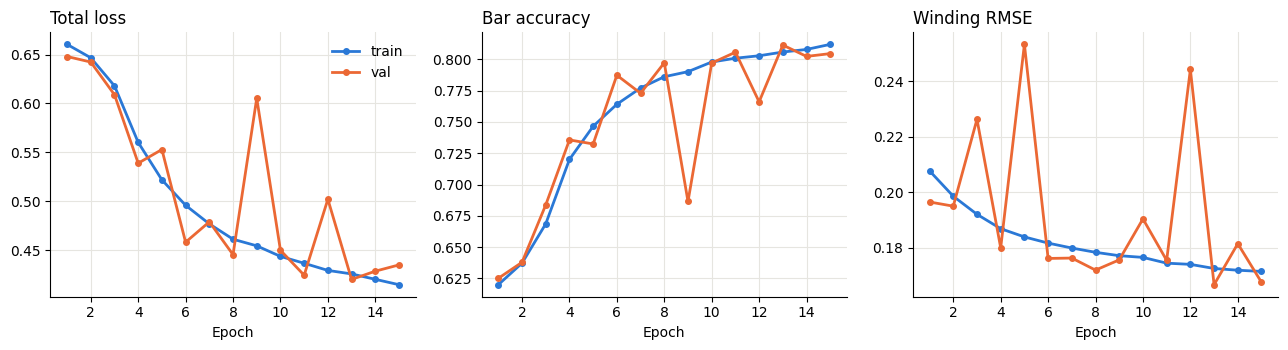

In [24]:
hist = pd.DataFrame(history.history)
panels = [("loss", "Total loss"), ("bar_acc", "Bar accuracy"), ("winding_rmse", "Winding RMSE")]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, (key, title) in zip(axes, panels):
    ax.plot(hist.index + 1, hist[key], color="#2a78d6", linewidth=2, marker="o", markersize=4, label="train")
    ax.plot(hist.index + 1, hist[f"val_{key}"], color="#eb6834", linewidth=2, marker="o", markersize=4, label="val")
    ax.set_title(title, loc="left")
    ax.set_xlabel("Epoch")
    ax.grid(color="#e6e5e0")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(frameon=False)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "cnn_baseline_history.png")
plt.show()

## 6. Evaluate on test against trivial baselines

A model is only interesting if it beats predicting the majority bar class and the mean winding
fractions (both taken from the training set). This is also the reference point for the >90%
accuracy and RMSE < 0.1 targets.

In [25]:
results = model.evaluate(test_ds, return_dict=True, verbose=0)

test, train = frames["test"], frames["train"]
bar_mask = test["bar_weight"] == 1
wind_mask = test["winding_weight"] == 1

majority = float(train.loc[train["bar_weight"] == 1, "bar_label"].mean() >= 0.5)
mean_winding = train.loc[train["winding_weight"] == 1, WINDING_COLS].mean().to_numpy()

comparison = pd.DataFrame({
    "trivial baseline": {
        "bar accuracy": (test.loc[bar_mask, "bar_label"] == majority).mean(),
        "winding RMSE": np.sqrt(((test.loc[wind_mask, WINDING_COLS].to_numpy() - mean_winding) ** 2).mean()),
    },
    "CNN": {"bar accuracy": results["bar_acc"], "winding RMSE": results["winding_rmse"]},
    "target": {"bar accuracy": 0.90, "winding RMSE": 0.10},
})
print(f"Test set: {int(bar_mask.sum()):,} bar labels, {int(wind_mask.sum()):,} winding labels | bar AUC {results['bar_auc']:.3f}")
comparison.style.format("{:.3f}")

Test set: 8,056 bar labels, 5,110 winding labels | bar AUC 0.886


,trivial baseline,CNN,target
bar accuracy,0.600,0.808,0.900
winding RMSE,0.205,0.171,0.100
